# O que acontece depois do diagnóstico de jogo patológico?

Pessoas que recebem o diagnóstico de **jogo patológico (F63.0)** nos CAPS passam a ter, no ano seguinte, outros
diagnósticos que não tinham antes, como ansiedade, depressão ou uso de drogas? E isso é mais ou menos comum do que
para quem chega ao CAPS por outro motivo?

**Comparação.** Para saber se "7% recebem um diagnóstico novo de ansiedade" é muito ou pouco, comparamos com quem
recebeu pela primeira vez outro diagnóstico: álcool, outras drogas, depressão ou ansiedade.

**Dados:** `uv run python -m src.saude_mental.sia_trajetorias` (todos os pacientes dos CAPS, 2018 a jun/2026, uma linha
por pessoa pseudonimizada × mês × grupo de diagnóstico). Só agregados aparecem aqui, com células de menos de 5 pessoas
suprimidas.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import math

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

from src.config import pasta
from src.saude_mental.sia_trajetorias import NOMES

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.1f}".format)
MIN_CELULA = 5
CORTE = (2026 - 2018) * 12 + 6 - 1  # jun/2026
t = pl.read_parquet(pasta("caps") / "sia_trajetorias.parquet").filter(pl.col("mes").is_between(0, CORTE))
print(f"{t['id'].n_unique():,} pacientes, {t.height:,} linhas (pessoa × mês × grupo)")

5,408,601 pacientes, 37,907,032 linhas (pessoa × mês × grupo)


## Decisões

**Quando começa (t0).** Para cada pessoa e grupo de diagnóstico, t0 é o **primeiro mês** em que o grupo aparece, como
CID principal ou associado. Só entram pessoas com t0 entre **jan/2019 e jun/2025**:
- a partir de 2019, para ter pelo menos 12 meses de histórico antes (os dados começam em jan/2018). Assim, "primeira
  vez" quer dizer pelo menos um ano sem esse diagnóstico registrado;
- até jun/2025, para todos terem 12 meses completos de seguimento depois (os dados vão até jun/2026).

**Diagnóstico novo.** Um grupo conta como "novo depois" se aparece nos 12 meses **depois** de t0 e não apareceu nos
12 meses **antes**. O próprio grupo de entrada não conta.

**Grupos comparados (entrada):** jogo patológico (F63.0), álcool (F10), outras drogas (F11–F19), humor/depressão
(F30–F39) e ansiedade/estresse (F40–F48).

**Padronização por sexo e idade.** Os pacientes de jogo são mais jovens, e quase metade são mulheres. Ansiedade e
depressão são mais comuns em mulheres, e drogas em homens jovens. Para não confundir isso com efeito do jogo,
recalculamos as taxas dos outros grupos **como se eles tivessem a mesma composição por sexo e faixa etária dos
pacientes de jogo** (padronização direta). A tabela mostra as duas versões: bruta e padronizada.

**Permanência no CAPS.** Fração que ainda tem algum atendimento no CAPS entre 6 e 12 meses depois de t0.

**Limites.** Só vemos o que é registrado no CAPS. Quem sai do CAPS some dos dados, então "diagnóstico novo depois" é
um piso. O t0 é a primeira vez que o diagnóstico aparece no CAPS desde 2018, não a primeira vez na vida.

In [2]:
ENTRADAS = [1, 2, 3, 5, 6]
DESFECHOS = [6, 5, 3, 2]

primeiro = t.group_by("id", "grupo").agg(pl.col("mes").min().alias("t0"))
perfil0 = t.join(primeiro, left_on=["id", "grupo", "mes"], right_on=["id", "grupo", "t0"]).group_by("id", "grupo").agg(pl.col("sexo").first(), pl.col("faixa").first())
coortes = (primeiro.filter(pl.col("grupo").is_in(ENTRADAS) & pl.col("t0").is_between(12, CORTE - 12))
           .join(perfil0, on=["id", "grupo"]).drop_nulls(["sexo", "faixa"]).rename({"grupo": "entrada"}))

# grupos de cada pessoa nas janelas antes/depois do seu t0
j = t.select("id", "mes", "grupo").join(coortes.select("id", "entrada", "t0"), on="id")
antes = j.filter((pl.col("mes") >= pl.col("t0") - 12) & (pl.col("mes") < pl.col("t0"))).select("id", "entrada", "grupo").unique()
depois = j.filter((pl.col("mes") > pl.col("t0")) & (pl.col("mes") <= pl.col("t0") + 12)).select("id", "entrada", "grupo").unique()
novo = depois.join(antes, on=["id", "entrada", "grupo"], how="anti").filter(pl.col("grupo") != pl.col("entrada"))
fica = (j.filter((pl.col("mes") > pl.col("t0") + 6) & (pl.col("mes") <= pl.col("t0") + 12)).select("id", "entrada").unique()
        .with_columns(pl.lit(True).alias("permanece")))

base = coortes.join(fica, on=["id", "entrada"], how="left").with_columns(pl.col("permanece").fill_null(False))
for g in DESFECHOS:
    ids = novo.filter(pl.col("grupo") == g).select("id", "entrada").with_columns(pl.lit(True).alias(f"novo_{g}"))
    base = base.join(ids, on=["id", "entrada"], how="left").with_columns(pl.col(f"novo_{g}").fill_null(False))
base.group_by("entrada").len().sort("entrada").with_columns(pl.col("entrada").replace_strict(NOMES).alias("grupo de entrada")).select("grupo de entrada", "len").to_pandas().set_index("grupo de entrada")

,len
grupo de entrada,
jogo patológico (F63.0),915
álcool (F10),401401
outras drogas (F11–F19),663591
humor/depressão (F30–F39),1027401
ansiedade/estresse (F40–F48),890065


## 1. Diagnóstico novo nos 12 meses seguintes, por grupo de entrada

In [3]:
desf = [f"novo_{g}" for g in DESFECHOS] + ["permanece"]
rot = {"novo_6": "ansiedade/estresse", "novo_5": "humor/depressão", "novo_3": "outras drogas", "novo_2": "álcool", "permanece": "ainda no CAPS 6–12 meses depois"}

# pesos: composição sexo × faixa dos pacientes de jogo
w = base.filter(pl.col("entrada") == 1).group_by("sexo", "faixa").len("n_jogo").with_columns((pl.col("n_jogo") / pl.col("n_jogo").sum()).alias("peso"))
estr = base.group_by("entrada", "sexo", "faixa").agg(pl.len().alias("n"), *[pl.col(c).mean().alias(c) for c in desf])

def wilson(p, n, z=1.96):
    if n == 0: return (float("nan"), float("nan"))
    c = (p + z * z / (2 * n)) / (1 + z * z / n); m = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (c - m, c + m)

linhas = []
for e in ENTRADAS:
    b = base.filter(pl.col("entrada") == e); n = b.height
    if n < MIN_CELULA: continue
    pad = estr.filter(pl.col("entrada") == e).join(w, on=["sexo", "faixa"], how="inner")
    for c in desf:
        bruto = b[c].mean()
        p_pad = (pad[c] * pad["peso"]).sum() / pad["peso"].sum()
        lo, hi = wilson(bruto, n)
        linhas.append({"entrada": NOMES[e], "pacientes": n, "desfecho": rot[c], "bruta %": bruto * 100,
                       "IC95 (bruta)": f"{lo*100:.1f}–{hi*100:.1f}", "padronizada %": p_pad * 100 if e != 1 else bruto * 100})
res = pd.DataFrame(linhas)
res.pivot(index="entrada", columns="desfecho", values="padronizada %")[[rot[c] for c in desf]]

desfecho,ansiedade/estresse,humor/depressão,outras drogas,álcool,ainda no CAPS 6–12 meses depois
entrada,,,,,
ansiedade/estresse (F40–F48),0.0,9.0,1.8,1.3,32.6
humor/depressão (F30–F39),7.9,0.0,2.3,1.6,38.4
jogo patológico (F63.0),7.9,6.9,4.9,1.9,31.8
outras drogas (F11–F19),1.9,2.8,0.0,7.1,31.1
álcool (F10),2.4,3.7,14.4,0.0,34.4


Taxas **padronizadas** pela composição de sexo e idade dos pacientes de jogo patológico (%). A linha do jogo é a taxa bruta.

In [4]:
res.pivot(index="entrada", columns="desfecho", values="bruta %")[[rot[c] for c in desf]]

desfecho,ansiedade/estresse,humor/depressão,outras drogas,álcool,ainda no CAPS 6–12 meses depois
entrada,,,,,
ansiedade/estresse (F40–F48),0.0,9.5,1.1,0.9,33.6
humor/depressão (F30–F39),8.4,0.0,1.5,1.2,39.1
jogo patológico (F63.0),7.9,6.9,4.9,1.9,31.8
outras drogas (F11–F19),1.5,2.3,0.0,7.8,30.6
álcool (F10),1.9,3.1,12.8,0.0,33.8


As mesmas taxas, **brutas** (sem padronização). Intervalos de confiança de 95% (Wilson) das taxas do jogo:

In [5]:
res[res["entrada"] == NOMES[1]][["desfecho", "bruta %", "IC95 (bruta)", "pacientes"]].set_index("desfecho")

,bruta %,IC95 (bruta),pacientes
desfecho,,,
ansiedade/estresse,7.9,6.3–9.8,915
humor/depressão,6.9,5.4–8.7,915
outras drogas,4.9,3.7–6.5,915
álcool,1.9,1.2–3.0,915
ainda no CAPS 6–12 meses depois,31.8,28.9–34.9,915


Text(0.5, 1.0, 'Diagnóstico novo nos 12 meses seguintes (padronizado por sexo e idade)')

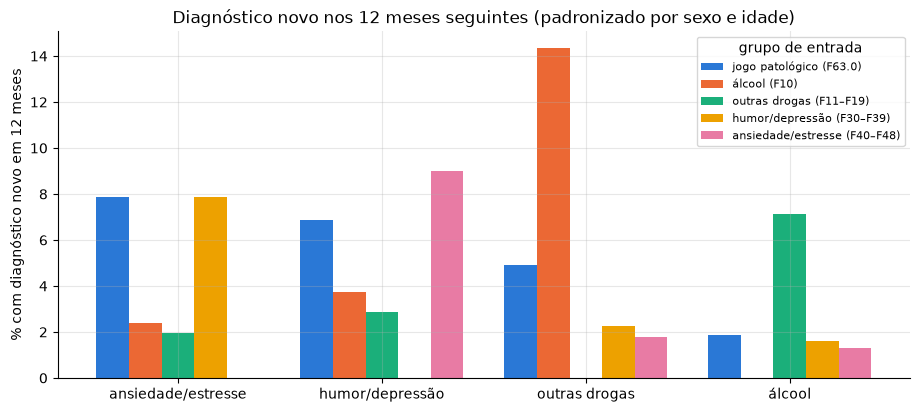

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
tab = res.pivot(index="entrada", columns="desfecho", values="padronizada %")[[rot[c] for c in desf[:-1]]]
ordem = [NOMES[e] for e in ENTRADAS if NOMES[e] in tab.index]
tab = tab.loc[ordem]
x = range(len(tab.columns)); larg = 0.8 / len(tab)
cores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
for i, (nome, lin) in enumerate(tab.iterrows()):
    ax.bar([k + i * larg for k in x], lin.values, width=larg, label=nome, color=cores[i])
ax.set_xticks([k + larg * (len(tab) - 1) / 2 for k in x], tab.columns); ax.set_ylabel("% com diagnóstico novo em 12 meses")
ax.legend(fontsize=8, title="grupo de entrada"); ax.set_title("Diagnóstico novo nos 12 meses seguintes (padronizado por sexo e idade)")

## 2. Por sexo, entre os pacientes de jogo patológico

In [7]:
sx = (base.filter(pl.col("entrada") == 1).group_by("sexo").agg(pl.len().alias("pacientes"), *[(pl.col(c).mean() * 100).alias(rot[c]) for c in desf])
      .with_columns(pl.col("sexo").replace_strict({0: "Homens", 1: "Mulheres"})))
sx.to_pandas().set_index("sexo")

,pacientes,ansiedade/estresse,humor/depressão,outras drogas,álcool,ainda no CAPS 6–12 meses depois
sexo,,,,,,
Homens,503,8.2,5.0,6.6,2.2,29.4
Mulheres,412,7.5,9.2,2.9,1.5,34.7


## 3. Ao longo do tempo: os pacientes de 2024–2025 são diferentes?

A alta do jogo patológico começou em 2024. Os pacientes que chegaram nessa leva têm o mesmo padrão dos anteriores?

In [8]:
coh = (base.filter(pl.col("entrada") == 1).with_columns(pl.when(pl.col("t0") < 72).then(pl.lit("2019–2023")).otherwise(pl.lit("2024–jun/2025")).alias("chegada"))
       .group_by("chegada").agg(pl.len().alias("pacientes"), *[(pl.col(c).mean() * 100).alias(rot[c]) for c in desf]).sort("chegada"))
coh.to_pandas().set_index("chegada")

,pacientes,ansiedade/estresse,humor/depressão,outras drogas,álcool,ainda no CAPS 6–12 meses depois
chegada,,,,,,
2019–2023,378,9.5,6.9,5.6,0.8,34.7
2024–jun/2025,537,6.7,6.9,4.5,2.6,29.8


## Leitura

**1. Ansiedade e depressão: os pacientes de jogo se parecem com os de saúde mental "comum".** No ano seguinte ao
primeiro diagnóstico de jogo patológico, 7,9% recebem um diagnóstico novo de ansiedade e 6,9% de depressão. É o mesmo
patamar de quem chega ao CAPS por depressão ou ansiedade (7–9%, padronizado por sexo e idade), e 3 a 4 vezes mais que
quem chega por álcool ou outras drogas.

**2. Drogas: ficam no meio do caminho entre a saúde mental "comum" e as dependências.** 4,9% recebem um diagnóstico
novo de uso de outras drogas (cocaína, crack, múltiplas). É 3 a 4 vezes mais que quem chega por ansiedade ou depressão
(1–1,5%), mas menos que quem chega por álcool (12,8%).

**3. Permanência igual à das dependências.** Só 32% ainda estão no CAPS de 6 a 12 meses depois, como nos casos de
álcool e drogas (31–34%), e menos que nos de depressão (39%). O abandono é alto, mas não é exclusivo do jogo.

**4. Homens e mulheres seguem caminhos diferentes.** Entre as mulheres com jogo patológico, 9,2% recebem depressão nova,
contra 5,0% dos homens. Entre os homens, 6,6% recebem drogas novas, contra 2,9% das mulheres.

**Em resumo:** o jogo patológico, nos CAPS, se comporta como uma dependência (permanência, uso de outras drogas) que traz
junto o sofrimento típico da ansiedade e da depressão. Isso pede um cuidado que combine as duas coisas.

**Limites:** só vemos o que é registrado no CAPS; quem sai da rede some dos dados, então as taxas são pisos. Os 915
pacientes de jogo dão intervalos de confiança razoáveis (ansiedade nova: 6,3%–9,8%), mas recortes menores (por sexo,
por época de chegada) são mais incertos.